<a href="https://colab.research.google.com/github/michael2005mp/MIchael_punguil_labs/blob/main/RNN_Airplane_Car_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RNN и GRU для распознавания самолётов и автомобилей

Лабораторная работа для **Google Colab**. Дополнительные `.py`-файлы и ручная загрузка наборов не нужны.

Метки: **airplane = 0**, **car (automobile) = 1**. Train обучает веса, val выбирает эпоху, test измеряет итоговое качество. Обычная RNN изучается на последовательности строк изображения; GRU используется для сравнения. Выходы ячеек заранее не заполнены.


## 1 Среда и параметры
Существующая сборка PyTorch сохраняется; устанавливаются только отсутствующие библиотеки. Для короткой проверки задайте `SMOKE = True`, затем для отчёта верните `False`.


In [14]:
from pathlib import Path
import importlib.util, subprocess, sys
for import_name, package in {"torch": "torch", "numpy": "numpy", "PIL": "Pillow", "matplotlib": "matplotlib"}.items():
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import argparse, csv, hashlib, io, json, random, tarfile, urllib.request, zipfile
import time, platform, uuid, shutil
from collections import Counter
from datetime import date, datetime
import numpy as np
from PIL import Image, ImageOps
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from IPython.display import display, SVG

ROOT = Path("/content/rnn_lab") if Path("/content").exists() else Path.cwd() / "colab_lab"
ROOT.mkdir(parents=True, exist_ok=True)
DATASETS = ["cifar10"]  # Самолёты и автомобили есть только в CIFAR-10
MODELS = ["rnn", "gru"]
EPOCHS = 12
HIDDEN = 64
SIZE = 32
BATCH = 64
LR = 0.001
SEED = 42
ORDER = "rows"  # "columns" — дополнительный эксперимент
SMOKE = False
CLASSES = ["airplane", "car"]  # CIFAR-10: airplane = 0, automobile = 1
print("Python:", platform.python_version(), "PyTorch:", torch.__version__)
print("Устройство:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Рабочая папка:", ROOT)


Python: 3.13.15 PyTorch: 2.11.0+cu130
Устройство: Tesla T4
Рабочая папка: /content/rnn_lab


## 2 Скачивание и подготовка данных

Используется зеркало бинарного CIFAR-10 в MindSpore. MD5 CIFAR-10 сверяется с [контрольной суммой авторов](https://cave.cs.toronto.edu/kriz/cifar.html).

CIFAR-10, только airplane и car: **8000 / 2000 / 2000** изображений train / val / test (по 5000 обучающих и 1000 тестовых картинок на класс; из train по 1000 на класс идут в val). Seed разбиения фиксирован отдельно от seed обучения. Точные дубликаты RGB-пикселей удаляются с приоритетом test, затем val, затем train; почти одинаковые фото не выявляются. Повторный запуск использует подготовленные данные.


In [15]:
SOURCES = {
    'cifar10': ('https://mindspore-website.obs.cn-north-4.myhuaweicloud.com/notebook/datasets/cifar-10-binary.tar.gz',
                'cifar-10-binary.tar.gz', 'c32a1d4ab5d03f1284b67883e8d87530')}

def obtain(raw, source):
    url, name, expected_md5 = source
    path = raw / name
    if not path.exists():
        print('Downloading', url, flush=True)
        partial = path.with_suffix('.part')
        with urllib.request.urlopen(url, timeout=120) as response, partial.open('wb') as out:
            while block := response.read(1024 * 1024):
                out.write(block)
        partial.replace(path)
    digest = hashlib.file_digest(path.open('rb'), 'md5').hexdigest()
    if expected_md5 and digest != expected_md5:
        raise ValueError(f'Invalid archive checksum: {path}')
    return path

def cifar_records(path):
    pools = {('train', c): [] for c in ('airplane', 'car')}
    pools.update({('test', c): [] for c in ('airplane', 'car')})
    with tarfile.open(path, 'r:gz') as tar:
        for member in sorted(tar.getmembers(), key=lambda m: m.name):
            name = Path(member.name).name
            if not member.isfile() or not (name.startswith('data_batch_') or name == 'test_batch.bin'):
                continue
            a = np.frombuffer(tar.extractfile(member).read(), dtype=np.uint8).reshape(-1, 3073)
            source_split = 'test' if name == 'test_batch.bin' else 'train'
            for idx in np.flatnonzero(np.isin(a[:, 0], [0, 1])):
                cls = 'airplane' if a[idx, 0] == 0 else 'car'
                rgb = a[idx, 1:].reshape(3, 32, 32).transpose(1, 2, 0)
                buf = io.BytesIO()
                Image.fromarray(rgb).save(buf, format='PNG')
                fn = f'{Path(name).stem}_{idx:05d}.png'
                pools[(source_split, cls)].append((fn, buf.getvalue(), f'{member.name}:{idx}'))
    records = []
    for (original, cls), items in sorted(pools.items()):
        random.Random(42 + int(cls == 'car')).shuffle(items)
        for i, (fn, data, src) in enumerate(items):
            split = 'test' if original == 'test' else ('val' if i < 1000 else 'train')
            records.append((split, cls, fn, data, src))
    return records

def write_dataset(root, name, records, archive):
    target = root / name
    if (target / 'metadata.json').exists():
        print('Already prepared:', target)
        return
    rows, removed, seen = [], [], {}
    # Keep test first, then validation: no exact decoded image may leak into train.
    records.sort(key=lambda r: ({'test': 0, 'val': 1, 'train': 2}[r[0]], r[1], r[2]))
    for split, cls, fn, data, source in records:
        with Image.open(io.BytesIO(data)) as im:
            rgb = im.convert('RGB')
            rgb.load()  # Validate every image, not only its header.
            digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
        rel = f'{split}/{cls}/{fn}'
        if digest in seen:
            removed.append({'file': rel, 'duplicate_of': seen[digest]})
            continue
        seen[digest] = rel
        dest = target / rel
        dest.parent.mkdir(parents=True, exist_ok=True)
        dest.write_bytes(data)
        rows.append({'path': rel, 'split': split, 'class': cls, 'label': int(cls == 'car'),
                     'source_id': source, 'pixel_sha256': digest})
    with (target / 'manifest.csv').open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)
    info = {'name': name, 'seed': 42, 'class_to_idx': {'airplane': 0, 'car': 1},
            'download_url': SOURCES[name][0], 'preparation_date': date.today().isoformat(),
            'source_page': 'https://cave.cs.toronto.edu/kriz/cifar.html',
            'archive_sha256': hashlib.file_digest(archive.open('rb'), 'sha256').hexdigest(),
            'counts': dict(Counter(f'{r["split"]}/{r["class"]}' for r in rows)),
            'total': len(rows), 'exact_duplicates_removed': removed,
            'note': 'Exact decoded RGB duplicates removed. Near-duplicates not audited.'}
    (target / 'metadata.json').write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding='utf-8')
    print(json.dumps(info, ensure_ascii=False), flush=True)


In [16]:
assert DATASETS and set(DATASETS) <= {"cifar10"}
assert MODELS and set(MODELS) <= {"rnn", "gru"}
RAW = ROOT / "raw"
DATA = ROOT / "data"
RAW.mkdir(exist_ok=True)
readers = {"cifar10": cifar_records}
for dataset in DATASETS:
    metadata_path = DATA / dataset / "metadata.json"
    if not metadata_path.exists():
        archive = obtain(RAW, SOURCES[dataset])
        write_dataset(DATA, dataset, readers[dataset](archive), archive)
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    print(dataset, metadata["counts"], "всего:", metadata["total"])


cifar10 {'test/airplane': 1000, 'test/car': 1000, 'val/airplane': 1000, 'val/car': 1000, 'train/airplane': 4000, 'train/car': 4000} всего: 12000


## 3 Просмотр изображений
Оцените различия в исходном разрешении и фоне. Эти примеры берутся только из train.


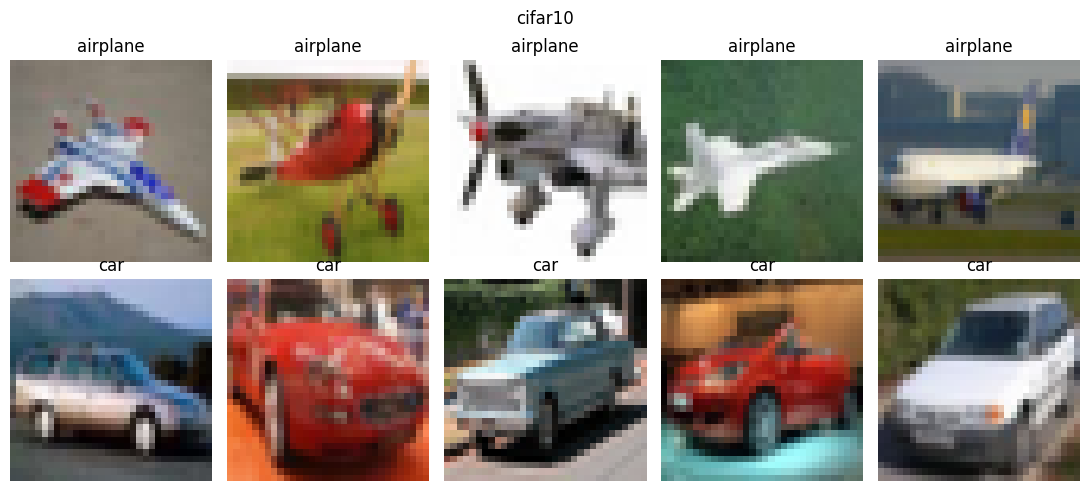

In [17]:
for dataset in DATASETS:
    fig, axes = plt.subplots(2, 5, figsize=(11, 5))
    for row, cls in enumerate(CLASSES):
        paths = sorted((DATA / dataset / "train" / cls).glob("*"))[:5]
        for ax, path in zip(axes[row], paths):
            with Image.open(path) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(cls); ax.axis("off")
    fig.suptitle(dataset); plt.tight_layout(); plt.show()


## 4 Изображение как последовательность
RGB → 32 × 32 → значения от −1 до 1. Тензор `[B, 3, 32, 32]` преобразуется в `[B, 32, 96]`: одна строка — один шаг. Данные каждого раздела загружаются в память для повторных эпох.


In [18]:
def preprocess(path, size=32):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert('RGB')
        im = im.resize((size, size), Image.Resampling.BILINEAR)
        # CHW image -> later reshape to H time steps of W*3 features.
        arr = np.asarray(im, dtype=np.float32) / 127.5 - 1.0
    return torch.from_numpy(arr.transpose(2, 0, 1).copy())

def load_split(root, split, size, limit=None):
    items = []
    for label, cls in enumerate(CLASSES):
        paths = sorted(p for p in (root / split / cls).iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
        if limit: paths = paths[:limit]
        items.extend((path, label) for path in paths)
    if not items: raise ValueError(f'No images in {root / split}')
    return TensorDataset(torch.stack([preprocess(p, size) for p, _ in items]),
                         torch.tensor([y for _, y in items], dtype=torch.long))


## 5 Рекуррентная модель
Каждое изображение начинает обработку с нулевого состояния. Последнее состояние подаётся на линейный классификатор. Выход — два логита; softmax не применяется перед CrossEntropyLoss.


In [19]:
class ImageRNN(nn.Module):
    def __init__(self, kind='rnn', size=32, hidden=64, order='rows'):
        super().__init__()
        self.order = order
        cell = {'rnn': nn.RNN, 'gru': nn.GRU}[kind]
        self.rnn = cell(input_size=size * 3, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 2)

    def forward(self, x):
        if self.order == 'columns':
            x = x.transpose(2, 3)
        # [B,C,H,W] -> [B,H,W,C] -> [B,H,W*C]
        seq = x.permute(0, 2, 3, 1).contiguous().flatten(2)
        _, hidden = self.rnn(seq)
        return self.head(hidden[-1])  # logits [B,2], no softmax here

x = torch.zeros(4, 3, SIZE, SIZE)
print("Изображения:", tuple(x.shape))
print("Последовательность:", tuple(x.permute(0, 2, 3, 1).flatten(2).shape))
for kind in MODELS:
    example_model = ImageRNN(kind, SIZE, HIDDEN, ORDER)
    print(kind, "выход:", tuple(example_model(x).shape),
          "параметров:", sum(p.numel() for p in example_model.parameters()))
    assert example_model(x).shape == (4, 2)


Изображения: (4, 3, 32, 32)
Последовательность: (4, 32, 96)
rnn выход: (4, 2) параметров: 10498
gru выход: (4, 2) параметров: 31234


## 6 Оценка и цикл обучения
Метрики: accuracy, precision, recall, macro-F1 и матрица ошибок. Лучшая эпоха выбирается по val_loss; test не участвует в настройке. Early stopping: четыре эпохи без улучшения. Ограничение нормы градиента — 1.0.


In [20]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    confusion = torch.zeros(2, 2, dtype=torch.int64)
    loss_sum = total = 0
    for x, y in loader:
        logits = model(x.to(device))
        loss_sum += nn.functional.cross_entropy(logits, y.to(device), reduction='sum').item()
        pred = logits.argmax(1).cpu()
        confusion += torch.bincount(y * 2 + pred, minlength=4).reshape(2, 2)
        total += len(y)
    cm = confusion.numpy()
    precision = np.diag(cm) / np.maximum(cm.sum(0), 1)
    recall = np.diag(cm) / np.maximum(cm.sum(1), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return {'loss': loss_sum / total, 'accuracy': float(np.trace(cm) / total),
            'macro_f1': float(f1.mean()), 'precision': precision.tolist(),
            'recall': recall.tolist(), 'confusion_matrix': cm.tolist(), 'n': total}

def save_curves(history, path):
    # Standalone SVG without an extra plotting dependency.
    lines = ['<svg xmlns="http://www.w3.org/2000/svg" width="900" height="350" viewBox="0 0 900 350">',
             '<rect width="900" height="350" fill="white"/>']
    for panel, keys, title in [(0, ('train_loss', 'val_loss'), 'Loss'), (1, ('train_accuracy', 'val_accuracy'), 'Accuracy')]:
        x0, y0, w, h = 55 + 445 * panel, 55, 350, 225
        ymax = max(1e-6, max(row[k] for row in history for k in keys)) * 1.1 if panel == 0 else 1
        lines.append(f'<text x="{x0}" y="25" font-family="sans-serif" font-size="18">{title}</text>')
        for i in range(5):
            val = ymax * i / 4; yy = y0 + h * (1-i/4)
            lines.append(f'<path d="M{x0},{yy} h{w}" stroke="#ddd"/><text x="{x0-45}" y="{yy+4}" font-size="12">{val:.2f}</text>')
        for k, color in zip(keys, ('#245c91', '#bc4b30')):
            points = ' '.join(f'{x0+i*w/max(len(history)-1,1):.1f},{y0+h*(1-row[k]/ymax):.1f}' for i,row in enumerate(history))
            lines.append(f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2"/>')
            lines.append(f'<text x="{x0 + (0 if k==keys[0] else 160)}" y="320" fill="{color}" font-family="sans-serif" font-size="13">{k}</text>')
        lines.append(f'<text x="{x0}" y="299" font-size="12">1</text><text x="{x0+w-10}" y="299" font-size="12">{len(history)}</text>')
    path.write_text('\n'.join(lines + ['</svg>']), encoding='utf-8')


In [21]:
def train(args):
    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed)
    torch.set_num_threads(min(4, torch.get_num_threads()))
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(args.seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    device = torch.device('cuda' if torch.cuda.is_available() and not args.cpu else 'cpu')
    root = args.data / args.dataset
    out = args.out / f'{args.dataset}_{args.model}_{args.order}_{args.seed}'
    if args.smoke: out = out.with_name(out.name + '_smoke')
    if out.exists(): raise FileExistsError(f'Choose a new --out directory; refusing to overwrite {out}')
    trainset = load_split(root, 'train', args.size, 64 if args.smoke else None)
    valset = load_split(root, 'val', args.size, 32 if args.smoke else None)
    generator = torch.Generator().manual_seed(args.seed)
    loader = DataLoader(trainset, batch_size=args.batch, shuffle=True, generator=generator, num_workers=0)
    val_loader = DataLoader(valset, batch_size=args.batch, num_workers=0)
    model = ImageRNN(args.model, args.size, args.hidden, args.order).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=args.lr)
    criterion = nn.CrossEntropyLoss()
    config = {k: str(v) if isinstance(v, Path) else v for k,v in vars(args).items()}
    config.update(torch_version=str(torch.__version__), python_version=platform.python_version(),
                  device=str(device), class_names=CLASSES, parameters=sum(p.numel() for p in model.parameters()))
    out.mkdir(parents=True)
    (out / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    best, stale, history, start = float('inf'), 0, [], time.perf_counter()
    for epoch in range(1, (1 if args.smoke else args.epochs) + 1):
        model.train(); loss_sum = correct = total = 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x); loss = criterion(logits, y)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item(); total += len(y)
        val = evaluate(model, val_loader, device)
        row = dict(epoch=epoch, train_loss=loss_sum/total, train_accuracy=correct/total,
                   val_loss=val['loss'], val_accuracy=val['accuracy'])
        history.append(row); print(json.dumps(row), flush=True)
        if val['loss'] < best:
            best, stale = val['loss'], 0
            torch.save({'state_dict': model.state_dict(), 'config': config, 'epoch': epoch}, out/'best.pt')
        else:
            stale += 1
            if stale >= args.patience: break
    with (out/'history.csv').open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=history[0]); writer.writeheader(); writer.writerows(history)
    save_curves(history, out/'curves.svg')
    if not args.smoke:
        checkpoint = torch.load(out/'best.pt', map_location=device, weights_only=True)
        model.load_state_dict(checkpoint['state_dict'])
        testset = load_split(root, 'test', args.size)
        metrics = evaluate(model, DataLoader(testset, batch_size=args.batch), device)
        majority = int(torch.bincount(trainset.tensors[1]).argmax())
        metrics.update(best_epoch=checkpoint['epoch'], seconds=time.perf_counter()-start,
                       majority_baseline_accuracy=float((testset.tensors[1] == majority).float().mean()),
                       class_names=CLASSES, matrix_rows='true labels', matrix_columns='predictions')
        (out/'test_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
        print(json.dumps(metrics), flush=True)
    print('Saved:', out)
    return out

def predict(checkpoint_path, image_path, cpu=False):
    device = torch.device('cuda' if torch.cuda.is_available() and not cpu else 'cpu')
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    cfg = checkpoint['config']
    model = ImageRNN(cfg['model'], cfg['size'], cfg['hidden'], cfg['order']).to(device)
    model.load_state_dict(checkpoint['state_dict']); model.eval()
    with torch.no_grad():
        probs = model(preprocess(image_path, cfg['size']).unsqueeze(0).to(device)).softmax(1)[0].cpu().tolist()
    result = {'prediction': CLASSES[int(np.argmax(probs))], 'probabilities': dict(zip(CLASSES, probs))}
    print(json.dumps(result)); return result


## 7 Обучение выбранных моделей

По умолчанию выполняются два эксперимента: RNN и GRU на наборе CIFAR-10 (самолёты и автомобили). В этой ячейке каждый повторный запуск создаёт отдельную папку результатов. `SMOKE=True` выполняет одну эпоху на 128 тренировочных и 64 валидационных изображениях без test; такой запуск проверяет программу, но не качество модели.


In [22]:
RUNS = ROOT / "runs" / (datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:6])
RUN_DIRS = []
for dataset in DATASETS:
    for kind in MODELS:
        args = argparse.Namespace(
            data=DATA, out=RUNS, dataset=dataset, model=kind,
            order=ORDER, size=SIZE, hidden=HIDDEN, batch=BATCH,
            epochs=EPOCHS, patience=4, lr=LR, seed=SEED,
            cpu=False, smoke=SMOKE)
        RUN_DIRS.append(train(args))
print("Результаты:", RUNS)


{"epoch": 1, "train_loss": 0.5359933526515961, "train_accuracy": 0.731, "val_loss": 0.48201326084136964, "val_accuracy": 0.782}
{"epoch": 2, "train_loss": 0.4452466595172882, "train_accuracy": 0.79475, "val_loss": 0.4132010235786438, "val_accuracy": 0.8125}
{"epoch": 3, "train_loss": 0.403309632062912, "train_accuracy": 0.8225, "val_loss": 0.4315409574508667, "val_accuracy": 0.795}
{"epoch": 4, "train_loss": 0.3880877820253372, "train_accuracy": 0.83175, "val_loss": 0.37956455135345457, "val_accuracy": 0.8425}
{"epoch": 5, "train_loss": 0.3546908450126648, "train_accuracy": 0.84625, "val_loss": 0.35427682161331175, "val_accuracy": 0.848}
{"epoch": 6, "train_loss": 0.3530504243373871, "train_accuracy": 0.850625, "val_loss": 0.33728642797470093, "val_accuracy": 0.859}
{"epoch": 7, "train_loss": 0.3287744108438492, "train_accuracy": 0.860125, "val_loss": 0.3228790807723999, "val_accuracy": 0.859}
{"epoch": 8, "train_loss": 0.31890115976333616, "train_accuracy": 0.862875, "val_loss": 0.317

## 8 Графики и таблица результатов
Сравнивайте модели внутри одного набора. Разные наборы отличаются размером, разрешением и содержанием фотографий. Не выбирайте гиперпараметры по test.


cifar10_rnn_rows_42


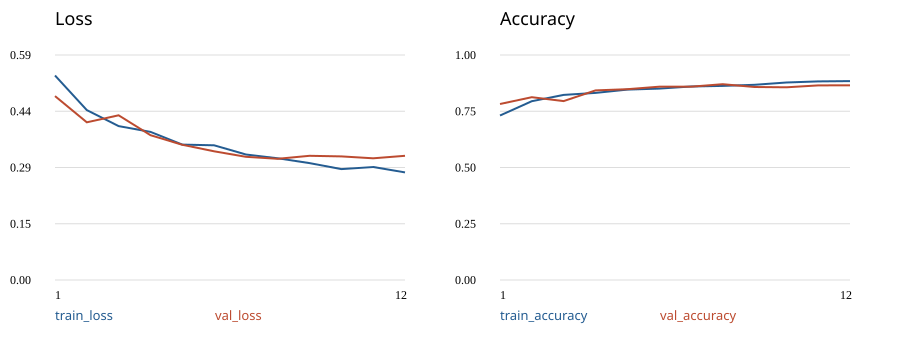

{
  "dataset": "cifar10",
  "model": "rnn",
  "best_epoch": 8,
  "accuracy": 0.876,
  "macro_f1": 0.8759095380532408,
  "baseline_accuracy": 0.5,
  "parameters": 10498,
  "seconds": 6.798011426999892
}


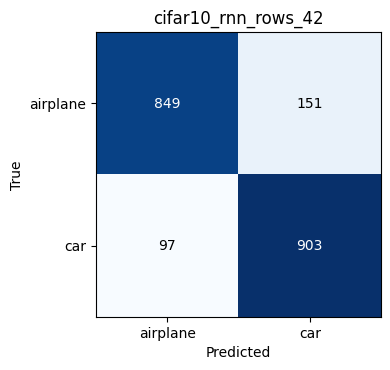

cifar10_gru_rows_42


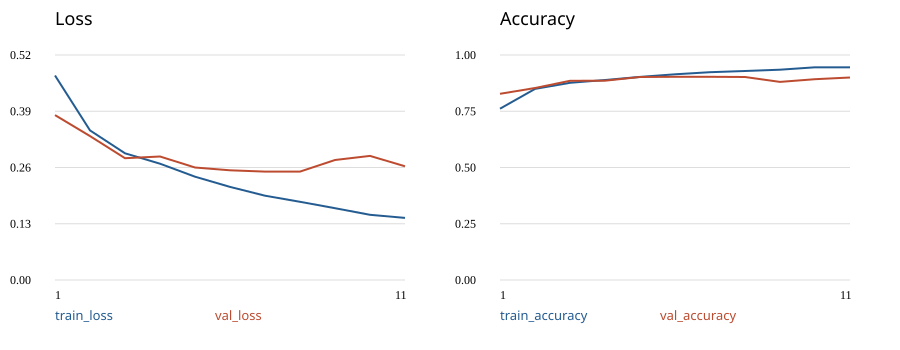

{
  "dataset": "cifar10",
  "model": "gru",
  "best_epoch": 7,
  "accuracy": 0.91,
  "macro_f1": 0.90999918999271,
  "baseline_accuracy": 0.5,
  "parameters": 31234,
  "seconds": 5.9898414230001435
}


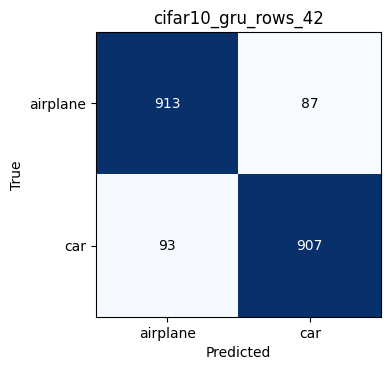

In [23]:
summary = []
for folder in RUN_DIRS:
    print(folder.name)
    display(SVG(filename=str(folder / "curves.svg")))
    metric_file = folder / "test_metrics.json"
    if not metric_file.exists():
        print("Технический запуск: тестовые метрики не вычислялись.")
        continue
    metrics = json.loads(metric_file.read_text())
    cfg = json.loads((folder / "config.json").read_text())
    row = {"dataset": cfg["dataset"], "model": cfg["model"],
           "best_epoch": metrics["best_epoch"], "accuracy": metrics["accuracy"],
           "macro_f1": metrics["macro_f1"],
           "baseline_accuracy": metrics["majority_baseline_accuracy"],
           "parameters": cfg["parameters"], "seconds": metrics["seconds"]}
    summary.append(row)
    print(json.dumps(row, indent=2))
    cm = np.array(metrics["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(cm, cmap="Blues")
    ax.set(xticks=[0,1], yticks=[0,1], xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel="Predicted", ylabel="True", title=folder.name)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i,j]), ha="center", va="center",
                    color="white" if cm[i,j] > cm.max()/2 else "black")
    fig.tight_layout(); fig.savefig(folder / "confusion_matrix.png", dpi=160)
    plt.show()
if summary:
    with (RUNS / "summary.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(summary[0]))
        writer.writeheader(); writer.writerows(summary)


## 9 Примеры ошибок
Ниже анализируется первая обученная модель (RNN). Измените `SELECTED_RUN`, чтобы выбрать другую. Просмотр test выполняется после фиксации эксперимента; по этим примерам параметры не подбираются.


Всего ошибок: 248


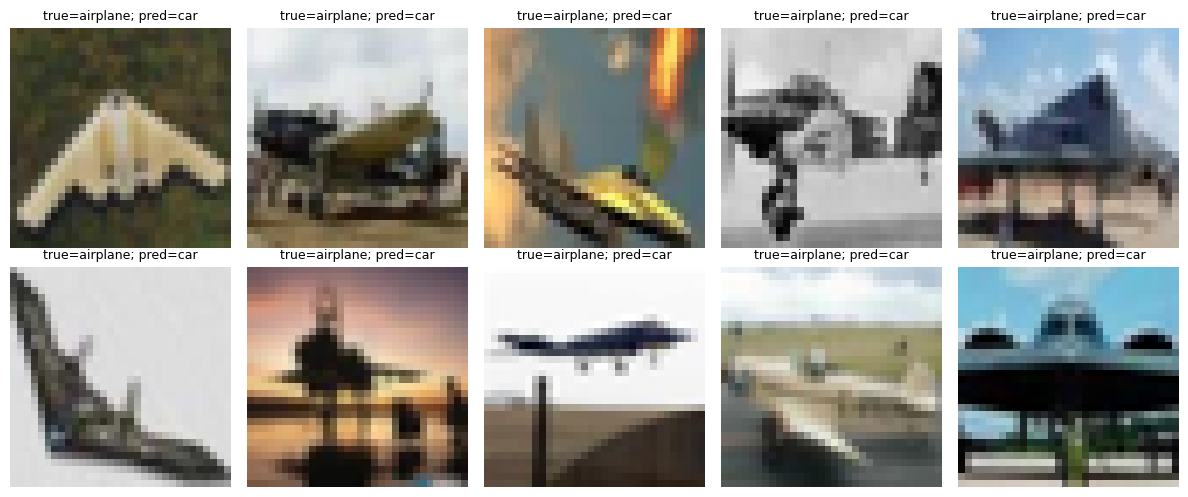

In [24]:
SELECTED_RUN = RUN_DIRS[0]
checkpoint_path = SELECTED_RUN / "best.pt"
if SMOKE:
    print("В режиме SMOKE тест и анализ ошибок пропущены.")
else:
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    cfg = checkpoint["config"]
    model = ImageRNN(cfg["model"], cfg["size"], cfg["hidden"], cfg["order"])
    model.load_state_dict(checkpoint["state_dict"]); model.eval()
    errors = []
    with torch.no_grad():
        for label, cls in enumerate(CLASSES):
            for path in sorted((DATA / cfg["dataset"] / "test" / cls).glob("*")):
                pred = model(preprocess(path, cfg["size"]).unsqueeze(0)).argmax(1).item()
                if pred != label:
                    errors.append((path, cls, CLASSES[pred]))
    print("Всего ошибок:", len(errors))
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for ax in axes.flat: ax.axis("off")
    for ax, (path, actual, predicted) in zip(axes.flat, errors[:10]):
        with Image.open(path) as im: ax.imshow(im.convert("RGB"))
        ax.set_title(f"true={actual}; pred={predicted}", fontsize=9)
    fig.tight_layout(); fig.savefig(SELECTED_RUN / "errors.png", dpi=160); plt.show()


## 10 Своя фотография по желанию
Измените `TRY_OWN_IMAGE` на `True`, выполните ячейку и выберите изображение на компьютере. Модель всегда выбирает airplane или car, даже если этих объектов на фотографии нет.


In [25]:
TRY_OWN_IMAGE = False  # поставьте True, чтобы загрузить свою фотографию
if TRY_OWN_IMAGE:
    from google.colab import files
    uploaded = files.upload()
    photo_dir = ROOT / "own_photos"
    photo_dir.mkdir(exist_ok=True)
    for filename, content in uploaded.items():
        photo_path = photo_dir / Path(filename).name
        photo_path.write_bytes(content)
        result = predict(checkpoint_path, photo_path)
        with Image.open(photo_path) as im:
            im.thumbnail((300,300)); display(im.copy())


## 11 Сохранение результатов
Архив содержит веса, параметры, историю, графики, метрики и сводную CSV-таблицу. В Colab появится загрузка ZIP на компьютер. Исходные датасеты в этот архив не включаются.


In [26]:
archive_path = Path(shutil.make_archive(str(RUNS), "zip", root_dir=RUNS))
print("Архив:", archive_path)
try:
    from google.colab import files
except ImportError:
    print("Локальный запуск: заберите ZIP по указанному пути.")
else:
    files.download(str(archive_path))


Архив: /content/rnn_lab/runs/20261012_195354_45a5a3.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>